Referencia: https://github.com/cmoralesd/fuzzy/blob/master/Taller%206%20-%20controlBelt.zip

<h2> Taller 6 - controlBelt - Lógica difusa para el control de posición</h2>

<br>Requiere el simulador CoppeliaSim con la escena controlBelt.ttt cargada.
<br>Requiere además que los archivos 'sim.py', 'simConst.py', 'remoteapi.dll' estén alojados en la misma carpeta que este cuaderno de Jupyter
<br><h4> Instrucciones</h4>
<br>1. Abra la escena controlBelt.ttt
<br>2. Inicie la simulación en CoppeliaSim.
<br>3. A continuación ejecute las celdas de código desde el cuaderno de Jupyter.


In [115]:
import sim
import numpy as np
# import fuzzy
import matplotlib.pyplot as plt
import skfuzzy as fuzz
import time

### 1. Definimos varias funciones para conectarnos con el simulador
Para mayor información sobre la API remota de CoppeliaSim para Python, refiérase a la documentación oficial en https://www.coppeliarobotics.com/helpFiles/en/remoteApiFunctionsPython.htm

In [4]:
def connect(port):
# Establece la conexión al simulador
# port debe coincidir con el puerto de conexión en CoppeliaSIm
# retorna el número de cliente o -1 si no puede establecer conexión
    sim.simxFinish(-1) # just in case, close all opened connections
    clientID=sim.simxStart('127.0.0.1',port,True,True,2000,5) # Conectarse
    if clientID == 0: print("conectado a", port)
    else: print("no se pudo conectar")
    return clientID


In [5]:
def moveBelt(V):
    # Envía el voltaje directamente a la señal de la correa
    return sim.simxSetFloatSignal(clientID, 'beltVelocity', float(V), sim.simx_opmode_oneshot)

In [6]:
def getPos(objName):
# obtiene la posición [x y z] de un objeto
# objName es un String con el nombre del objeto
    res,handler=sim.simxGetObjectHandle(clientID,objName,sim.simx_opmode_blocking)
    if res==0:
        res, pos=sim.simxGetObjectPosition(clientID,handler,-1,sim.simx_opmode_blocking)
        if res==0:
            return pos
    else:
        return -1

In [7]:
def getSimTime():
# obtiene el instante de tiempo de simulación en que se ejecutó 
# la última instrucción en el simulador
    return sim.simxGetLastCmdTime(clientID)

### 2. Verificamos la comunicación

In [144]:
# Conectarse al servidor de VREP
# *** ejecutar cada vez que se reinicia la simulación ***
clientID = connect(19999)

Conectado a CoppeliaSim en puerto 19999


In [145]:
# moveBelt(volt) envía al motor un voltaje en Volts
moveBelt(0)

1

In [151]:
# Obtiene la posición del objeto "Sphere"
getPos("Sphere")[0]

-0.12578733265399933

<h3> 3. Probamos el control proporcional</h3>
La velocidad de la correa será proporcional a la diferencia de distancia entre la posición deseada (target) y la posición de la esfera. Con Kp = 0.8, será nuestra referencia para comparar el controlador difuso.

Conectado a CoppeliaSim en puerto 19999
-- Iteración 1 --
Error: -0.29358181953430174
Voltaje de Motor: -4.403727293014526
-- Iteración 2 --
Error: -0.2884474158287048
Voltaje de Motor: -4.3267112374305725
-- Iteración 3 --
Error: -0.2416971981525421
Voltaje de Motor: -3.6254579722881313
-- Iteración 4 --
Error: -0.16210359930992124
Voltaje de Motor: -2.4315539896488185
-- Iteración 5 --
Error: -0.09794536828994749
Voltaje de Motor: -1.4691805243492122
-- Iteración 6 --
Error: -0.05690709352493284
Voltaje de Motor: -0.8536064028739926
-- Iteración 7 --
Error: -0.03565040826797483
Voltaje de Motor: -0.5347561240196225
-- Iteración 8 --
Error: -0.027386462688446023
Voltaje de Motor: -0.41079694032669034
-- Iteración 9 --
Error: -0.01754341125488279
Voltaje de Motor: -0.26315116882324185
-- Iteración 10 --
Error: -0.009600615501403786
Voltaje de Motor: -0.1440092325210568
-- Iteración 11 --
Error: -0.0059302806854247825
Voltaje de Motor: -0.08895421028137174
-- Iteración 12 --
Error: -0.0

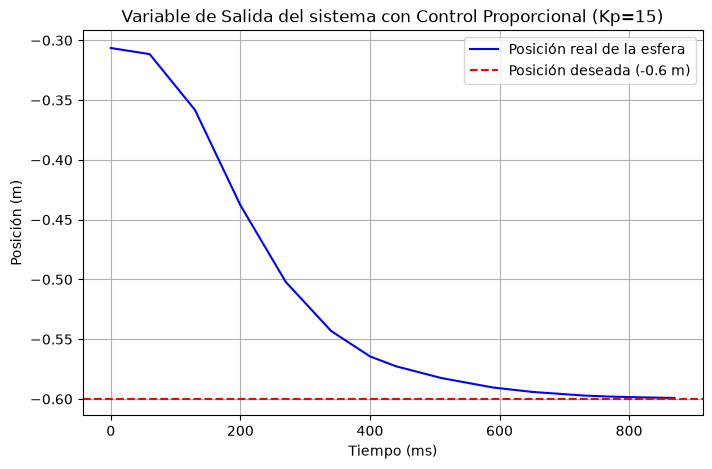

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_6940\2716382939.py:76: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


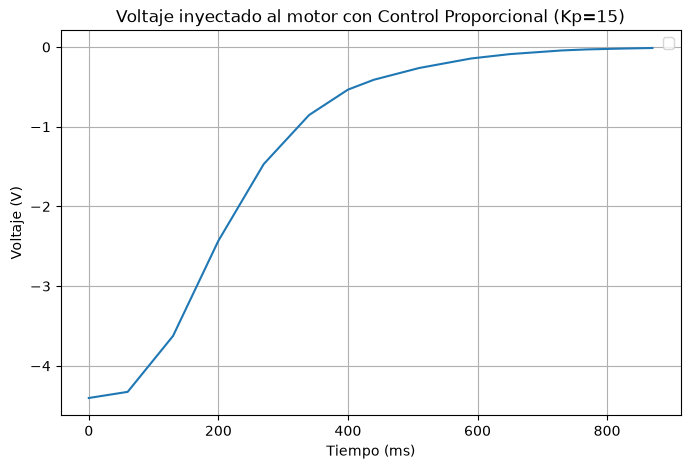

In [ ]:
clientID = connect(19999)
moveBelt(0)

kp = 15
t_final = 5000  # ms
pos_deseada = 0.6

l_t = []
l_pos = []
l_vmotor = []

t_inicio = None  # Se inicializará cuando tengamos la primera lectura

i = 0
while True:
    i = i + 1
    print(f"-- Iteración {i} --")
    pos_data = getPos("Sphere")
    if pos_data == -1:
        continue  # Reintentar si la lectura falla

    # En la primera lectura exitosa, registramos el tiempo de inicio real
    if t_inicio is None:
        t_inicio = getSimTime()

    pos_actual = pos_data[0]
    t_actual = getSimTime() - t_inicio  # Inicia exactamente en 0 ms

    l_pos.append(pos_actual)
    l_t.append(t_actual)

    # Control proporcional
    e = pos_deseada - pos_actual
    print(f"Error: {e}")
    vmotor = np.clip(kp * e, -10.0, 10.0)
    print(f"Voltaje de Motor: {vmotor}")
    moveBelt(vmotor)

    l_vmotor.append(vmotor)

    # Condiciones de parada
    if abs(e) < 0.001:
        print(f"\nLlegó a la posición deseada en {t_actual} ms.")
        break
    if abs(pos_actual) > 0.7:
        print("\nSalió de los límites.")
        break
    if t_actual >= t_final:
        print(f"\nTiempo límite alcanzado ({t_actual} ms).")
        break

# Detener el motor al terminar
moveBelt(0)

# Graficar resultados
plt.figure(figsize=(8, 5))
plt.plot(l_t, l_pos, label="Posición real de la esfera", color="blue")
plt.axhline(
    y=pos_deseada,
    color="r",
    linestyle="--",
    label=f"Posición deseada ({pos_deseada} m)",
)
plt.xlabel("Tiempo (ms)")
plt.ylabel("Posición (m)")
plt.title(f"Variable de Salida del sistema con Control Proporcional (Kp={kp})")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(l_t, l_vmotor)
plt.xlabel("Tiempo (ms)")
plt.ylabel("Voltaje (V)")
plt.title(f"Voltaje inyectado al motor con Control Proporcional (Kp={kp})")
plt.legend()
plt.grid(True)
plt.show()

<h3> 4. Taller 6 - Diseño del controlador difuso para la correa transportadora</h3>
Aplique el procedimiento de diseño ensayado anteriormente para conseguir un controlador difuso para el sistema de correa transportadora y esfera.<br><br>
Considere los siguientes requerimientos de diseño:<br>
- La posición de la bola debe ser controlada en el rango de trabajo desde -0.6 a 0.6 mts.<br>
- El motor debe recibir voltajes entres -10 y 10 volts.<br>
- Diseñe su controlador para privilegiar el tiempo de respuesta, manteniendo el controlador estable dentro del rango de movimientos permitidos (debe ser estable para los movimientos desde -0.6 a 0.6 y también desde 0.6 a -0.6).<br>
<br> Desarrolle su solución en este mismo cuaderno de Jupyter. Muestre los gráficos para las funciones de membresía de entrada y salida, la curva de respuesta del cntrolador y también un gráfico para la respuesta ante un movimiento desde -0.6 a 0.6 mts.

In [156]:
def calculo_vmotor(error_actual, graficar = False):
    #---- 1. Definición de variables y funciones de pertenencia
    #-- Universos de discursos
    x_error = np.linspace(-1.4,1.4,1000)
    y_vmotor = np.linspace(-10,10,1000)

    #-- Funciones de pertenencia
    # Error: MN, PN, C0, PP, MP
    c_error_MN = fuzz.trapmf(x_error, [-1.4, -1.4, -0.70, -0.4])
    c_error_PN = fuzz.trimf(x_error, [-0.5, -0.25, 0.0])
    c_error_C0 = fuzz.trimf(x_error, [-0.1, 0.0, 0.1])
    c_error_PP = fuzz.trimf(x_error, [0.0, 0.25, 0.5])
    c_error_MP = fuzz.trapmf(x_error, [0.4, 0.7, 1.4, 1.4])

    # Voltaje:
    c_vmotor_MN = fuzz.trapmf(y_vmotor, [-10, -10, -9.0, -7.0])
    c_vmotor_PN = fuzz.trimf(y_vmotor, [-7.5, -3.75, 0.0])
    c_vmotor_C0 = fuzz.trimf(y_vmotor, [-1.5, 0.0, 1.5])
    c_vmotor_PP = fuzz.trimf(y_vmotor, [0.0, 3.75, 7.5])
    c_vmotor_MP = fuzz.trapmf(y_vmotor, [7.0, 9.0, 10, 10])

    #-- Creación de las gráficas
    if graficar:
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8))

        # Gráfica de Error
        ax1.plot(x_error, c_error_MN, 'b', linewidth=2, label='MN (Muy Negativo)')
        ax1.plot(x_error, c_error_PN, 'g', linewidth=2, label='PN (Poco Negativo)')
        ax1.plot(x_error, c_error_C0, 'r', linewidth=2, label='C0 (Cercano a 0)')
        ax1.plot(x_error, c_error_PP, 'c', linewidth=2, label='PP (Poco Positivo)')
        ax1.plot(x_error, c_error_MP, 'm', linewidth=2, label='MP (Muy Positivo)')
        ax1.set_title('Funciones de Pertenencia - Error de Posición')
        ax1.set_xlabel('Error (m)')
        ax1.set_ylabel('Grado de Pertenencia μ(x)')
        ax1.set_ylim(-0.05, 1.05)
        ax1.grid(True, linestyle='--', alpha=0.7)
        ax1.legend(loc='upper right')

        # Gráfica de Voltaje del Motor
        ax2.plot(y_vmotor, c_vmotor_MN, 'b', linewidth=2, label='MN (Muy Negativo)')
        ax2.plot(y_vmotor, c_vmotor_PN, 'g', linewidth=2, label='PN (Poco Negativo)')
        ax2.plot(y_vmotor, c_vmotor_C0, 'r', linewidth=2, label='C0 (Cercano a 0)')
        ax2.plot(y_vmotor, c_vmotor_PP, 'c', linewidth=2, label='PP (Poco Positivo)')
        ax2.plot(y_vmotor, c_vmotor_MP, 'm', linewidth=2, label='MP (Muy Positivo)')
        ax2.set_title('Funciones de Pertenencia - Voltaje del Motor')
        ax2.set_xlabel('Voltaje (V)')
        ax2.set_ylabel('Grado de Pertenencia μ(y)')
        ax2.set_ylim(-0.05, 1.05)
        ax2.grid(True, linestyle='--', alpha=0.7)
        ax2.legend(loc='upper right')

        plt.tight_layout()
        plt.show()

    #---- 2. Fuzzificación del valor de entrada
    error_MN = fuzz.interp_membership(x_error, c_error_MN, error_actual)
    error_PN = fuzz.interp_membership(x_error, c_error_PN, error_actual)
    error_C0 = fuzz.interp_membership(x_error, c_error_C0, error_actual)
    error_PP = fuzz.interp_membership(x_error, c_error_PP, error_actual)
    error_MP = fuzz.interp_membership(x_error, c_error_MP, error_actual)

    #---- 3.1. Inferencia y aplicación de reglas difusa
    # Regla 1: Si error_MN, entonces vmotor_MN
    pertenencia_v_motor_MN = error_MN 
    conjunto_1 = np.fmin(pertenencia_v_motor_MN, c_vmotor_MN)

    # Regla 2: Si error_PN, entonces vmotor_PN
    pertenencia_v_motor_PN = error_PN 
    conjunto_2 = np.fmin(pertenencia_v_motor_PN, c_vmotor_PN)

    # Regla 3: Si error_C0, entonces vmotor_C0
    pertenencia_v_motor_C0 = error_C0 
    conjunto_3 = np.fmin(pertenencia_v_motor_C0, c_vmotor_C0)

    # Regla 4: Si error_PP, entonces vmotor_PP
    pertenencia_v_motor_PP = error_PP
    conjunto_4 = np.fmin(pertenencia_v_motor_PP, c_vmotor_PP)

    # Regla 5: Si error_MP, entonces vmotor_MP
    pertenencia_v_motor_MP = error_MP 
    conjunto_5 = np.fmin(pertenencia_v_motor_MP, c_vmotor_MP)

    union_conjuntos = np.fmax(conjunto_1, np.fmax(conjunto_2, np.fmax(conjunto_3, np.fmax(conjunto_4, conjunto_5))))

    # if graficar:
    #     plt.figure()
    #     plt.plot(y_vmotor, union_conjuntos)
    #     plt.show()
    
    # 4. Defuzzificación
    v_raw = fuzz.defuzz(y_vmotor, union_conjuntos, 'centroid')

    # 5. Saturación
    vmotor = np.clip(v_raw, -7.5, 7.5)

    return vmotor

Conectado a CoppeliaSim en puerto 19999


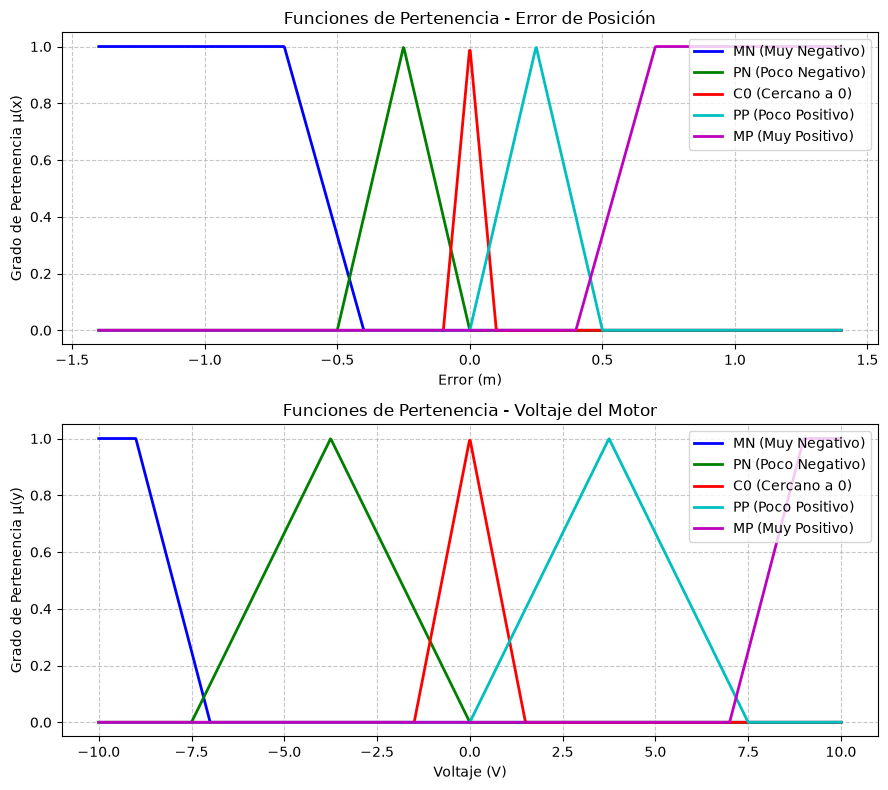

-- Iteración 1 --
Error: 0.5310
Voltaje de Motor: 7.5000


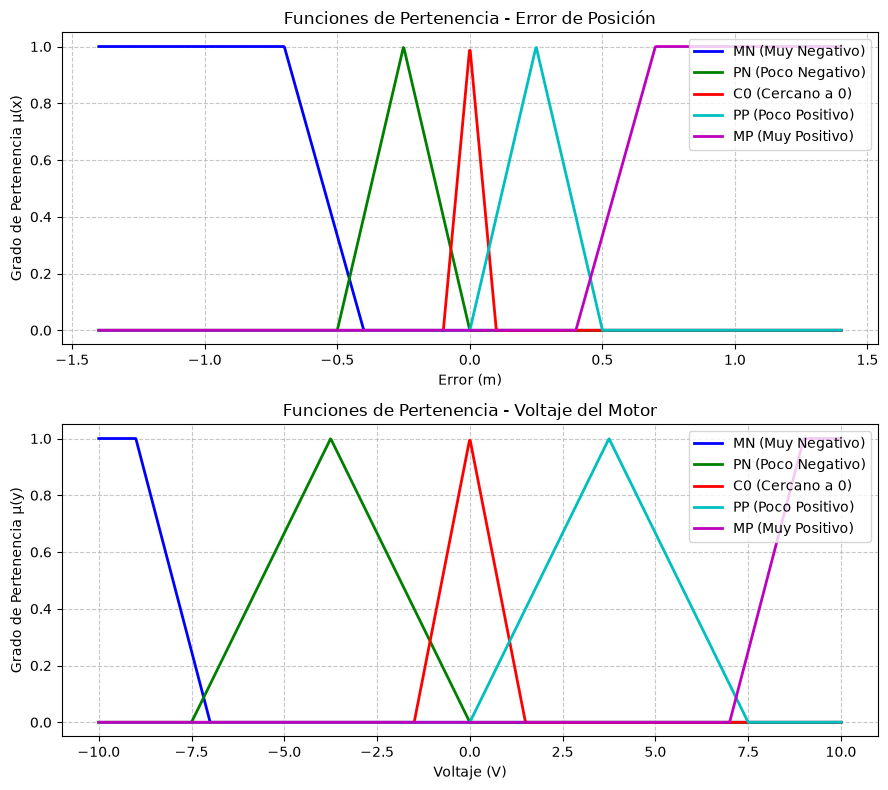

-- Iteración 2 --
Error: 0.5225
Voltaje de Motor: 7.5000


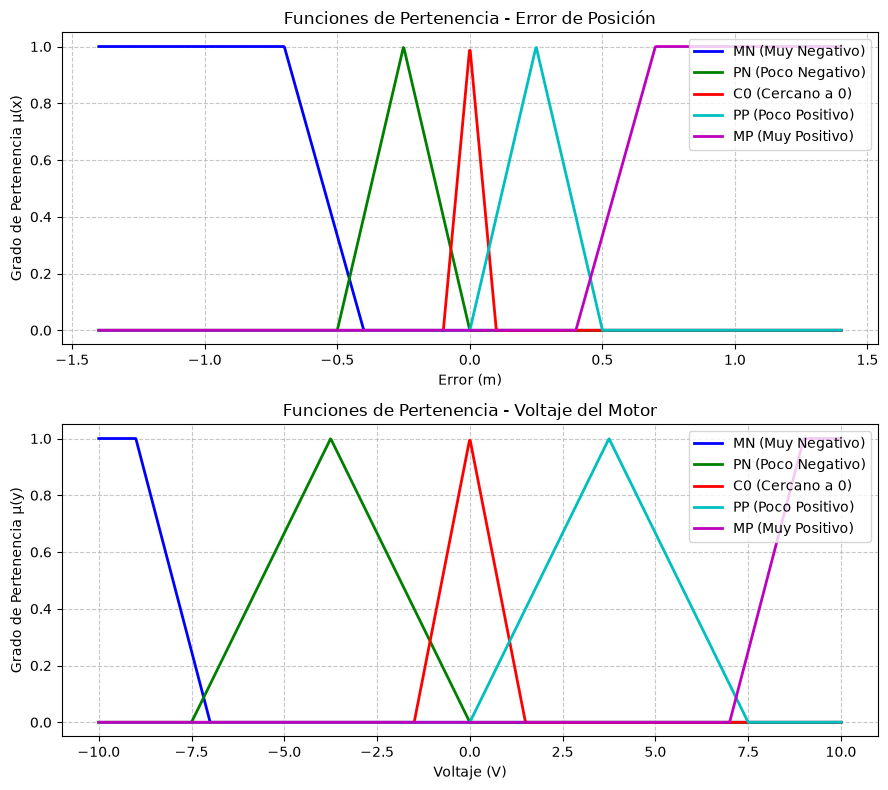

-- Iteración 3 --
Error: -0.1830
Voltaje de Motor: -3.7500


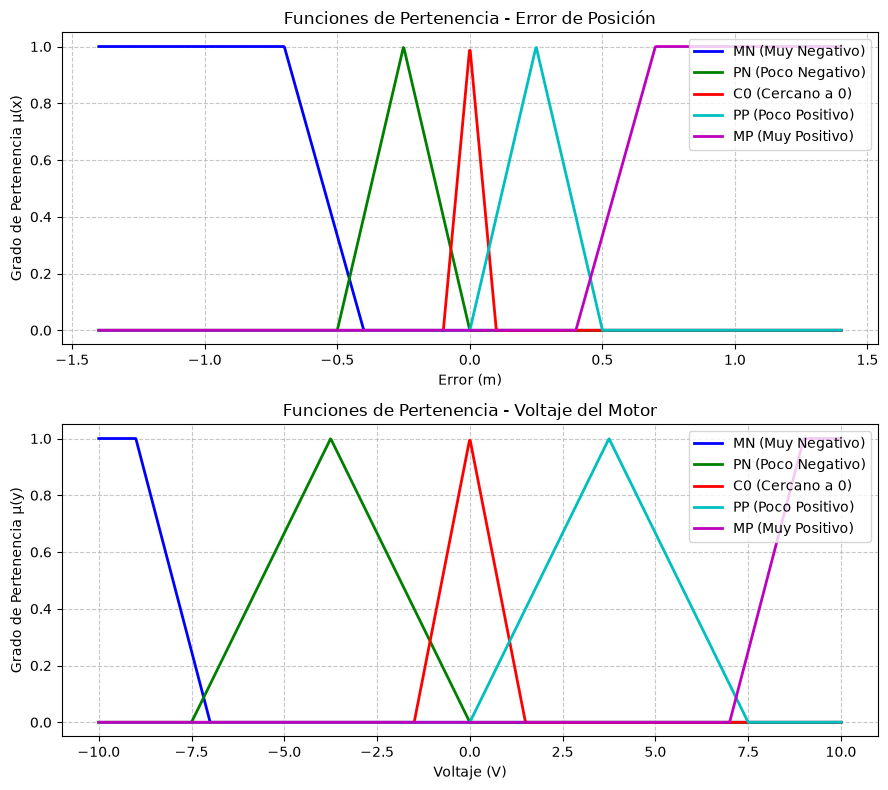

-- Iteración 4 --
Error: -1.1138
Voltaje de Motor: -7.5000

La bola salió de los límites (1.5138 m).


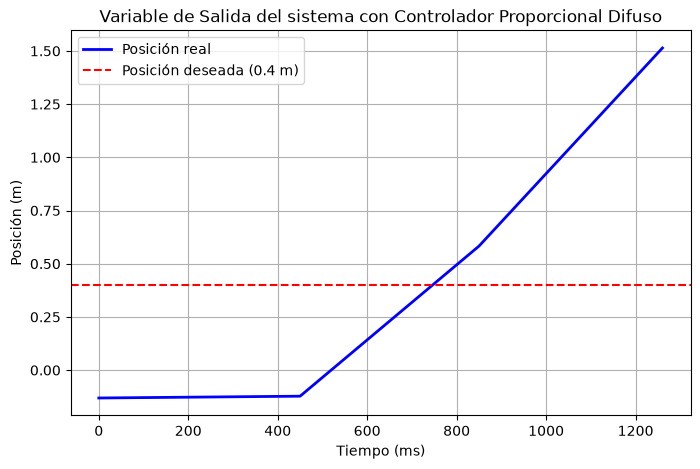

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_6940\1547816929.py:83: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


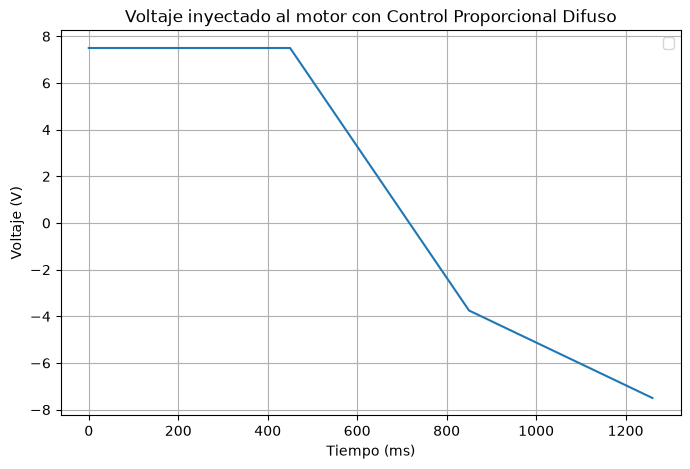

In [157]:
clientID = connect(19999)

if clientID == 0:
    moveBelt(0)

    pos_deseada = 0.4 # Setpoint
    t_final = 10000  # ms

    l_t = []
    l_pos = []
    l_vmotor = []

    t_inicio = None
    i = 0

    while True:
        pos_data = getPos("Sphere")
        if pos_data == -1:
            continue

        if t_inicio is None:
            t_inicio = getSimTime()

        i += 1
        pos_actual = pos_data[0]
        t_actual = getSimTime() - t_inicio

        e = pos_deseada - pos_actual

        e_sat = np.clip(e, -1.4, 1.4)
        vmotor = calculo_vmotor(e_sat, graficar = True)

        print(f"-- Iteración {i} --")
        print(f"Error: {e:.4f}")
        print(f"Voltaje de Motor: {vmotor:.4f}")

        moveBelt(vmotor)

        # Guardar historial
        l_t.append(t_actual)
        l_pos.append(pos_actual)
        l_vmotor.append(vmotor)

        # Criterios de parada
        if abs(e) < 0.001:
            print(f"\nLlegó a la posición deseada en {t_actual} ms.")
            break

        if abs(pos_actual) > 0.8:
            print(f"\nLa bola salió de los límites ({pos_actual:.4f} m)."
            )
            break

        if t_actual >= t_final:
            print(f"\nTiempo máximo de simulación alcanzado ({t_actual} ms).")
            break

        time.sleep(0.005)

    moveBelt(0)

    # Graficar
    plt.figure(figsize=(8, 5))
    plt.plot(l_t, l_pos, label="Posición real", color="blue", lw=2)
    plt.axhline(
        y=pos_deseada,
        color="red",
        linestyle="--",
        label=f"Posición deseada ({pos_deseada} m)",
    )
    plt.xlabel("Tiempo (ms)")
    plt.ylabel("Posición (m)")
    plt.title("Variable de Salida del sistema con Controlador Proporcional Difuso")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(l_t, l_vmotor)
    plt.xlabel("Tiempo (ms)")
    plt.ylabel("Voltaje (V)")
    plt.title(f"Voltaje inyectado al motor con Control Proporcional Difuso")
    plt.legend()
    plt.grid(True)
    plt.show()